# QG testbed — realism scenarios: when does 4DVar lose its advantage?

`qg2l_pipeline.ipynb` is a favourable case for 4DVar: same equations / parameters / forcing for the truth and the
DA model (truncation-only model error), observations without representativeness error, exactly known R, B estimated
from the truth, perfect H, periodic domain, unlimited optimisation budget. This notebook switches these
assumptions off one at a time (and all together), and compares for each scenario

* **4DVarNet** (retrained on each new dataset),
* **4DVar strong / weak** constraint (L-BFGS on the B^{1/2}-preconditioned cost, near convergence), and the same
  4DVar with **R estimated by the Desroziers diagnostic** (no truth) or **oracle R** (actual obs - truth std),
* **incremental 4DVar** as run operationally (Gauss-Newton outer loops + preconditioned conjugate gradient with
  tangent-linear / adjoint models), at an operational-like budget (3 x 20) and at a **low budget** (1 x 5),
* the **hybrid 4DVarNet → 4DVar** (4DVarNet reconstruction as background of each window), with a small sweep
  (window 3 or 7 days, b_scale 0.1 / 0.2, weak constraint, Desroziers R),

with the usual scores and the **error energy per Lyapunov subspace** (unstable / neutral / stable / residual),
with **paired block-bootstrap confidence intervals** on the ratios between methods.
Expected picture: 4DVarNet's advantage on the unstable subspace persists, while 4DVar's advantage on the stable
subspace (dynamics for free) shrinks as model and observation errors become realistic.

Everything is cached by configuration hash (`contrib/qg2l/pipeline.py`): scenarios that share a dataset share the
trained 4DVarNet, and re-running only recomputes what changed. Each new dataset = one 4DVarNet training
(tens of minutes on a GPU in the small size), so choose the scenarios to run in `RUN`.

In [1]:
import os, sys, json, copy
from pathlib import Path

REPO = Path.cwd().resolve()
while not (REPO / "main.py").exists():
    REPO = REPO.parent
os.chdir(REPO)
sys.path.insert(0, str(REPO))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import Image, Video, display

from contrib.qg2l import pipeline, obs as O
from contrib.qg2l.simulate import PRESETS

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

device: cuda


## 0. Base configuration (same small set-up as `qg2l_pipeline.ipynb`)

In [2]:
SIZE = "small"   # "small" | "full"
ROOT = Path("data/qg2l_scenarios_" + SIZE)
PRESET = "energetic"

if SIZE == "small":
    L, NX, NX_TRUTH, SPINUP = 5e5, 32, 64, 300
    SPLITS = dict(train=[0, 1095], val=[1095, 1185], test=[1215, 1305], total=1395)
    NET = dict(n_time=21, epochs=120)
    LYAP = dict(k=192, n_fwd=30, n_bwd=60, animation_days=30, figure_methods=None)
    WINDOW, SPIN_VAR = 7, 30
else:
    L, NX, NX_TRUTH, SPINUP = 1e6, 64, 128, 1095
    SPLITS = dict(train=[0, 1095], val=[1095, 1277], test=[1307, 1672], total=1762)
    NET = dict(n_time=21, epochs=150)
    LYAP = dict(k=512, n_fwd=30, n_bwd=60, animation_days=60, figure_methods=None)
    WINDOW, SPIN_VAR = 10, 60

# constellation with the real ground-track spacing whatever the box size
CONST = {n: dict(s, tracks_per_dir=max(1, round(s["tracks_per_dir"] * L / 1e6))) for n, s in O.DEFAULT_CONSTELLATION.items()}
BASE_GEN = dict(preset=PRESET, nx=NX, nx_truth=NX_TRUTH, L=L, spinup_days=SPINUP, splits=SPLITS, constellation=CONST,
                animation_days=30)

# DA methods compared in every scenario (any run_4dvar kwarg can be set; 'background': '4dvarnet' -> hybrid).
# All 4DVars use the B^{1/2} control-variable transform (preconditioning). Solvers:
#   lbfgs       : nonlinear L-BFGS on the preconditioned cost, run to (near) convergence -> reference
#   incremental : operational-style Gauss-Newton, n_outer re-linearisations x n_inner preconditioned CG
#                 iterations with tangent-linear / adjoint models
COMMON = dict(window_days=WINDOW, b_scale=0.5, spinup_days=SPIN_VAR)
METHODS = [
    dict(name="4dvar_strong", mode="strong", solver="lbfgs", n_iter=40, **COMMON),
    dict(name="4dvar_weak", mode="weak", solver="lbfgs", n_iter=40, q_scale=0.2, **COMMON),
    dict(name="4dvar_incr", mode="strong", solver="incremental", n_outer=3, n_inner=20, **COMMON),
    # low budget: 1 outer loop x 5 CG iterations ~ 6 (TL + AD) integrations per window
    dict(name="4dvar_incr_budget", mode="strong", solver="incremental", n_outer=1, n_inner=5, **COMMON),
    dict(name="hybrid", mode="strong", solver="incremental", n_outer=1, n_inner=10, window_days=WINDOW,
         b_scale=0.2, spinup_days=0, background="4dvarnet"),
    # --- observation-error statistics: R from the Desroziers diagnostic (no truth) and oracle R (truth)
    dict(name="4dvar_R_desroziers", mode="strong", solver="lbfgs", n_iter=40, r_mode="desroziers", **COMMON),
    dict(name="4dvar_R_oracle", mode="strong", solver="lbfgs", n_iter=40, r_mode="oracle", **COMMON),
    # --- hybrid sweep: shorter windows, more trust in 4DVarNet, weak constraint, Desroziers R
    dict(name="hybrid_w3", mode="strong", solver="incremental", n_outer=1, n_inner=10, window_days=3,
         b_scale=0.2, spinup_days=0, background="4dvarnet"),
    dict(name="hybrid_b01", mode="strong", solver="incremental", n_outer=1, n_inner=10, window_days=WINDOW,
         b_scale=0.1, spinup_days=0, background="4dvarnet"),
    dict(name="hybrid_weak", mode="weak", solver="incremental", n_outer=1, n_inner=10, window_days=WINDOW,
         b_scale=0.2, q_scale=0.2, spinup_days=0, background="4dvarnet"),
    dict(name="hybrid_w3_Rdes", mode="strong", solver="incremental", n_outer=1, n_inner=10, window_days=3,
         b_scale=0.2, spinup_days=0, background="4dvarnet", r_mode="desroziers"),
]
# methods shown in the diagnostic maps / animation (all methods are in the numbers and the other figures)
FIG_METHODS = ["4dvarnet", "4dvar_strong", "4dvar_R_desroziers", "hybrid_w3"]
LYAP["figure_methods"] = FIG_METHODS

## 1. Scenarios

| scenario | what changes | assumption broken |
|---|---|---|
| `baseline` | nothing | — |
| `obs_hr` | obs sample the block-averaged **high-resolution** SSH | no representativeness error |
| `obs_signal` | + an **unresolved SSH signal** (internal-tide-like, 1 cm, 40–120 km, 1-day decorrelation) in the obs only | obs = model-resolvable truth + white noise |
| `swot_roll` | SWOT **roll-like correlated error** (1 cm / 100 km), R still diagonal in 4DVar | R known and diagonal |
| `param_error` | truth with **different physics** (bottom drag ×1.5, β ×0.8) | perfect model equations |
| `forcing` | truth with an **unknown stochastic forcing** (2 mm/day, 150–400 km) | perfect model forcing |
| `B_free_run` | 4DVar **B from a free run of the DA model** instead of the truth | oracle B |
| `nadir_only` | no SWOT | (observability: larger λ₁·τ_obs) |
| `realistic` | everything above together (with SWOT) | all |

In [3]:
P = PRESETS[PRESET]
SIGNAL = dict(ssh_std=0.01, wavelength_km=(40.0, 120.0), decorrelation_days=1.0)
CONST_ROLL = {n: dict(s, roll_std=0.01 if s["kind"] == "swot" else 0.0) for n, s in CONST.items()}
CONST_NADIR = {n: s for n, s in CONST.items() if s["kind"] == "nadir"}
PARAMS = dict(rek=1.5 * P["rek"], beta=0.8 * P["beta"])
FORCING = dict(ssh_std=0.002, wavelength_km=(150.0, 400.0))

SCENARIOS = {
    "baseline":    dict(gen={}),
    "obs_hr":      dict(gen=dict(obs_source="hr_block")),
    "obs_signal":  dict(gen=dict(obs_source="hr_block", unresolved_signal=SIGNAL)),
    "swot_roll":   dict(gen=dict(constellation=CONST_ROLL)),
    "param_error": dict(gen=dict(truth_overrides=PARAMS)),
    "forcing":     dict(gen=dict(forcing=FORCING)),
    "B_free_run":  dict(gen={}, var=dict(b_source="free_run")),
    "nadir_only":  dict(gen=dict(constellation=CONST_NADIR)),
    "realistic":   dict(gen=dict(obs_source="hr_block", unresolved_signal=SIGNAL, constellation=CONST_ROLL,
                                 truth_overrides=PARAMS, forcing=FORCING), var=dict(b_source="free_run")),
}

# scenarios to run now (each new dataset = one 4DVarNet training)
RUN = ["baseline", "obs_signal", "param_error", "B_free_run", "realistic"]

## 2. Run

**Following progress.** The cell below runs everything sequentially; while it runs, the kernel is busy, so follow it
from a terminal on the cluster (same folder, same conda env):

```bash
python -m contrib.qg2l.pipeline data/qg2l_scenarios_small         # one-shot status
watch -n 60 python -m contrib.qg2l.pipeline data/qg2l_scenarios_small
tail -f data/qg2l_scenarios_small/4dvarnet/*/logs/version_*/metrics.csv   # per-epoch metrics
```

**After a crash (GPU, job time limit, kernel restart)**: restart the kernel and re-run all cells. Nothing finished is
recomputed and nothing unfinished restarts from scratch:
datasets are reused once complete; 4DVarNet resumes from `checkpoints/last.ckpt` (or only re-tests if training
was finished); each 4DVar resumes from its last completed window (`<method>.nc.partial.npz`); the Lyapunov
diagnostic resumes from its last saved step (`diag/lyap_checkpoint/`, every 10 days). `qg2l_pipeline.ipynb` resumes
its 4DVar and diagnostic the same way.

In [4]:
RESULTS = {}
for name in RUN:
    sc = SCENARIOS[name]
    gen = {**BASE_GEN, **sc.get("gen", {})}
    methods = [{**m, **sc.get("var", {})} for m in METHODS]
    print(f"\n========== {name} ==========")
    try:
        RESULTS[name] = pipeline.run_scenario(ROOT, name, gen, methods, net=NET, lyap=LYAP, device=DEVICE)
    except Exception as e:  # keep going with the other scenarios
        import traceback; traceback.print_exc()
        print(f"!!! scenario {name} failed: {e}")


========== baseline ==========


/Odyssey/private/m19beauc/conda_envs/4dvarnet-starter/lib/python3.11/site-packages/kornia/feature/lightglue.py:30: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_fwd(cast_inputs=torch.float32)
Global seed set to 333
/Odyssey/private/m19beauc/conda_envs/4dvarnet-starter/lib/python3.11/site-packages/lightning_fabric/plugins/environments/slurm.py:168: PossibleUserWarning: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /Odyssey/private/m19beauc/conda_envs/4dvarnet-starte ...
  rank_zero_warn(
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
Global seed set to 333


[4dvarnet] reuse data/qg2l_scenarios_small/4dvarnet/88b2d60a47_801e0e90c1
[4dvar] reuse data/qg2l_scenarios_small/scenarios/baseline/4dvar_strong.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/baseline/4dvar_weak.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/baseline/4dvar_incr.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/baseline/4dvar_incr_budget.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/baseline/hybrid.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/baseline/4dvar_R_desroziers.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/baseline/4dvar_R_oracle.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/baseline/hybrid_w3.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/baseline/hybrid_b01.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/baseline/hybrid_weak.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/baseline/hybrid_w3_Rdes.nc

========== obs_signal ==========


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
Global seed set to 333


[4dvarnet] reuse data/qg2l_scenarios_small/4dvarnet/6fa3f2541c_801e0e90c1
[4dvar] reuse data/qg2l_scenarios_small/scenarios/obs_signal/4dvar_strong.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/obs_signal/4dvar_weak.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/obs_signal/4dvar_incr.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/obs_signal/4dvar_incr_budget.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/obs_signal/hybrid.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/obs_signal/4dvar_R_desroziers.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/obs_signal/4dvar_R_oracle.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/obs_signal/hybrid_w3.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/obs_signal/hybrid_b01.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/obs_signal/hybrid_weak.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/obs_signal/hybrid_w3_Rdes.nc

========== param_error ==========


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs


[4dvarnet] reuse data/qg2l_scenarios_small/4dvarnet/ec820d8c5e_801e0e90c1
[4dvar] reuse data/qg2l_scenarios_small/scenarios/param_error/4dvar_strong.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/param_error/4dvar_weak.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/param_error/4dvar_incr.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/param_error/4dvar_incr_budget.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/param_error/hybrid.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/param_error/4dvar_R_desroziers.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/param_error/4dvar_R_oracle.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/param_error/hybrid_w3.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/param_error/hybrid_b01.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/param_error/hybrid_weak.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/param_error/hybrid_w3_Rdes.nc


Global seed set to 333
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs



========== B_free_run ==========
[4dvarnet] reuse data/qg2l_scenarios_small/4dvarnet/88b2d60a47_801e0e90c1
[4dvar] reuse data/qg2l_scenarios_small/scenarios/B_free_run/4dvar_strong.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/B_free_run/4dvar_weak.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/B_free_run/4dvar_incr.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/B_free_run/4dvar_incr_budget.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/B_free_run/hybrid.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/B_free_run/4dvar_R_desroziers.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/B_free_run/4dvar_R_oracle.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/B_free_run/hybrid_w3.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/B_free_run/hybrid_b01.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/B_free_run/hybrid_weak.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/B_free_run/hybrid_w3_Rdes.nc

========== realistic ==========


Global seed set to 333
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs


[4dvarnet] reuse data/qg2l_scenarios_small/4dvarnet/ce07178d8e_801e0e90c1
[4dvar] reuse data/qg2l_scenarios_small/scenarios/realistic/4dvar_strong.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/realistic/4dvar_weak.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/realistic/4dvar_incr.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/realistic/4dvar_incr_budget.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/realistic/hybrid.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/realistic/4dvar_R_desroziers.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/realistic/4dvar_R_oracle.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/realistic/hybrid_w3.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/realistic/hybrid_b01.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/realistic/hybrid_weak.nc
[4dvar] reuse data/qg2l_scenarios_small/scenarios/realistic/hybrid_w3_Rdes.nc


In [5]:
pipeline.progress(ROOT)   # state of datasets / trainings / scenarios (also after a restart)

== data/qg2l_scenarios_small
-- datasets
  6fa3f2541c: ready (41.4 h ago) {'obs_source': 'hr_block', 'unresolved_signal': {'decorrelation_days': 1.0, 'ssh_std': 0.01, 'wavelength_km': [40.0, 120.0]}}
  88b2d60a47: ready (46.8 h ago) baseline
  ce07178d8e: ready (17.5 h ago) {'obs_source': 'hr_block', 'forcing': {'ssh_std': 0.002, 'wavelength_km': [150.0, 400.0]}, 'unresolved_signal': {'decorrelation_days': 1.0, 'ssh_std': 0.01, 'wavelength_km': [40.0, 120.0]}, 'truth_overrides': {'beta': 1.2e-11, 'rek': 8.680499999999999e-07}, 'swot_roll': True}
  ec820d8c5e: ready (36.7 h ago) {'truth_overrides': {'beta': 1.2e-11, 'rek': 8.680499999999999e-07}}
-- 4DVarNet trainings
  6fa3f2541c_801e0e90c1: done, epoch 120/120, best val_mse 0.3091, last ckpt 37.6 h ago
  88b2d60a47_801e0e90c1: done, epoch 120/120, best val_mse 0.1692, last ckpt 42.2 h ago
  ce07178d8e_801e0e90c1: done, epoch 120/120, best val_mse 0.281, last ckpt 13.5 h ago
  ec820d8c5e_801e0e90c1: done, epoch 120/120, best val_mse 0.

## 3. Observation statistics and dynamical regime per scenario

In [6]:
pd.DataFrame({n: {k: r["obs_summary"][k] for k in ["lambda1_per_day_LRmodel", "median_revisit_days",
                                                   "lambda1_x_revisit", "ssh_std_m", "obs_minus_truth_std_m"]}
              for n, r in RESULTS.items()}).T.round(4)

,lambda1_per_day_LRmodel,median_revisit_days,lambda1_x_revisit,ssh_std_m,obs_minus_truth_std_m
baseline,0.0932,10.4887,0.9773,0.0717,0.0060
obs_signal,0.0932,10.4887,0.9773,0.0717,0.0147
param_error,0.0946,10.4887,0.9923,0.0610,0.0060
B_free_run,0.0932,10.4887,0.9773,0.0717,0.0060
realistic,0.0959,10.4887,1.0054,0.0674,0.0153


## 4. Scores (SSH and deep layer)

In [7]:
scores = pd.concat({n: pd.DataFrame(r["scores"]).T for n, r in RESULTS.items()}, names=["scenario", "method"])
scores.round(4)

rmse_ssh  mu_ssh  lx_ssh_km  rmse_layer2  \
scenario    method                                                         
baseline    4dvarnet              0.0051  0.9240    51.2664       0.0054   
            4dvar_strong          0.0090  0.8662    60.4072       0.0047   
            4dvar_weak            0.0099  0.8537    59.7037       0.0041   
            4dvar_incr            0.0085  0.8744    59.2326       0.0045   
            4dvar_incr_budget     0.0216  0.6801   105.5827       0.0089   
            hybrid                0.0068  0.8994    53.8320       0.0049   
            4dvar_R_desroziers    0.0084  0.8756    60.1450       0.0042   
            4dvar_R_oracle        0.0090  0.8659    60.3918       0.0047   
            hybrid_w3             0.0062  0.9087    50.8577       0.0053   
            hybrid_b01            0.0066  0.9021    53.8719       0.0049   
            hybrid_weak           0.0067  0.9004    53.8292       0.0050   
            hybrid_w3_Rdes        0.0057  0.9160    51.0074       0.0053   
obs_signal  4dvarnet              0.0079  0.8835    60.9745       0.0061   
            4dvar_strong          0.0161  0.7612    82.1677       0.0073   
            4dvar_weak            0.0183  0.7287    84.4232       0.0073   
            4dvar_incr            0.0168  0.7501    82.3460       0.0077   
            4dvar_incr_budget     0.0215  0.6815   105.3811       0.0084   
            hybrid                0.0133  0.8022    66.0679       0.0060   
            4dvar_R_desroziers    0.0136  0.7981    73.7810       0.0054   
            4dvar_R_oracle        0.0135  0.8000    74.3446       0.0050   
            hybrid_w3             0.0125  0.8143    61.0376       0.0065   
            hybrid_b01            0.0127  0.8117    65.5415       0.0059   
            hybrid_weak           0.0133  0.8024    65.8375       0.0061   
            hybrid_w3_Rdes        0.0101  0.8501    60.9580       0.0061   
param_error 4dvarnet              0.0049  0.9154    50.2321       0.0042   
            4dvar_strong          0.0095  0.8373    60.0275       0.0056   
            4dvar_weak            0.0103  0.8243    60.1243       0.0054   
            4dvar_incr            0.0096  0.8351    59.3719       0.0058   
            4dvar_incr_budget     0.0209  0.6424   102.7427       0.0082   
            hybrid                0.0065  0.8882    53.1360       0.0037   
            4dvar_R_desroziers    0.0089  0.8471    59.7768       0.0055   
            4dvar_R_oracle        0.0095  0.8377    60.0099       0.0056   
            hybrid_w3             0.0059  0.8988    49.5267       0.0041   
            hybrid_b01            0.0064  0.8914    53.1528       0.0036   
            hybrid_weak           0.0064  0.8899    52.9053       0.0037   
            hybrid_w3_Rdes        0.0055  0.9061    49.6499       0.0040   
B_free_run  4dvarnet              0.0051  0.9240    51.2664       0.0054   
            4dvar_strong          0.0088  0.8699    59.7311       0.0046   
            4dvar_weak            0.0096  0.8573    59.3785       0.0040   
            4dvar_incr            0.0082  0.8777    58.6609       0.0044   
            4dvar_incr_budget     0.0226  0.6643   107.4819       0.0091   
            hybrid                0.0067  0.9000    53.7785       0.0049   
            4dvar_R_desroziers    0.0082  0.8777    59.6695       0.0042   
            4dvar_R_oracle        0.0088  0.8698    59.7651       0.0046   
            hybrid_w3             0.0061  0.9092    50.7682       0.0053   
            hybrid_b01            0.0065  0.9029    53.8348       0.0049   
            hybrid_weak           0.0067  0.9002    53.7490       0.0050   
            hybrid_w3_Rdes        0.0056  0.9171    50.9918       0.0052   
realistic   4dvarnet              0.0091  0.8669    60.4511       0.0057   
            4dvar_strong          0.0187  0.7267    80.4611       0.0105   
            4dvar_weak            0.0200  0.7075    80.3864       0.0085   
    

In [8]:
# number of model integrations (nonlinear / tangent linear / adjoint) over the whole test run
pd.concat({n: pd.DataFrame(r["cost"]).T for n, r in RESULTS.items() if r.get("cost")}, names=["scenario", "method"])

n_nonlinear  n_tl  n_adjoint
scenario    method                                          
baseline    4dvar_strong                780     0        780
            4dvar_weak                  788     0        788
            4dvar_incr                   72  1080       1134
            4dvar_incr_budget            36    90        108
            hybrid                       26   130        143
            4dvar_R_desroziers          780     0        780
            4dvar_R_oracle              783     0        783
            hybrid_w3                    60   300        330
            hybrid_b01                   26   130        143
            hybrid_weak                  26   130        143
            hybrid_w3_Rdes               60   300        330
obs_signal  4dvar_strong                776     0        776
            4dvar_weak                  781     0        781
            4dvar_incr                   72  1080       1134
            4dvar_incr_budget            36    90        108
            hybrid                       26   130        143
            4dvar_R_desroziers          782     0        782
            4dvar_R_oracle              785     0        785
            hybrid_w3                    60   300        330
            hybrid_b01                   26   130        143
            hybrid_weak                  26   130        143
            hybrid_w3_Rdes               60   300        330
param_error 4dvar_strong                778     0        778
            4dvar_weak                  783     0        783
            4dvar_incr                   72  1080       1134
            4dvar_incr_budget            36    90        108
            hybrid                       26   130        143
            4dvar_R_desroziers          780     0        780
            4dvar_R_oracle              781     0        781
            hybrid_w3                    60   300        330
            hybrid_b01                   26   130        143
            hybrid_weak                  26   130        143
            hybrid_w3_Rdes               60   300        330
B_free_run  4dvar_strong                789     0        789
            4dvar_weak                  789     0        789
            4dvar_incr                   72  1080       1134
            4dvar_incr_budget            36    90        108
            hybrid                       26   130        143
            4dvar_R_desroziers          787     0        787
            4dvar_R_oracle              791     0        791
            hybrid_w3                    60   300        330
            hybrid_b01                   26   130        143
            hybrid_weak                  26   130        143
            hybrid_w3_Rdes               60   300        330
realistic   4dvar_strong                782     0        782
            4dvar_weak                  793     0        793
            4dvar_incr                   72  1080       1134
            4dvar_incr_budget            36    90        108
            hybrid                       26   130        143
            4dvar_R_desroziers          777     0        777
            4dvar_R_oracle              788     0        788
            hybrid_w3                    60   300        330
            hybrid_b01                   26   130        143
            hybrid_weak                  26   130        143
            hybrid_w3_Rdes               60   300        330

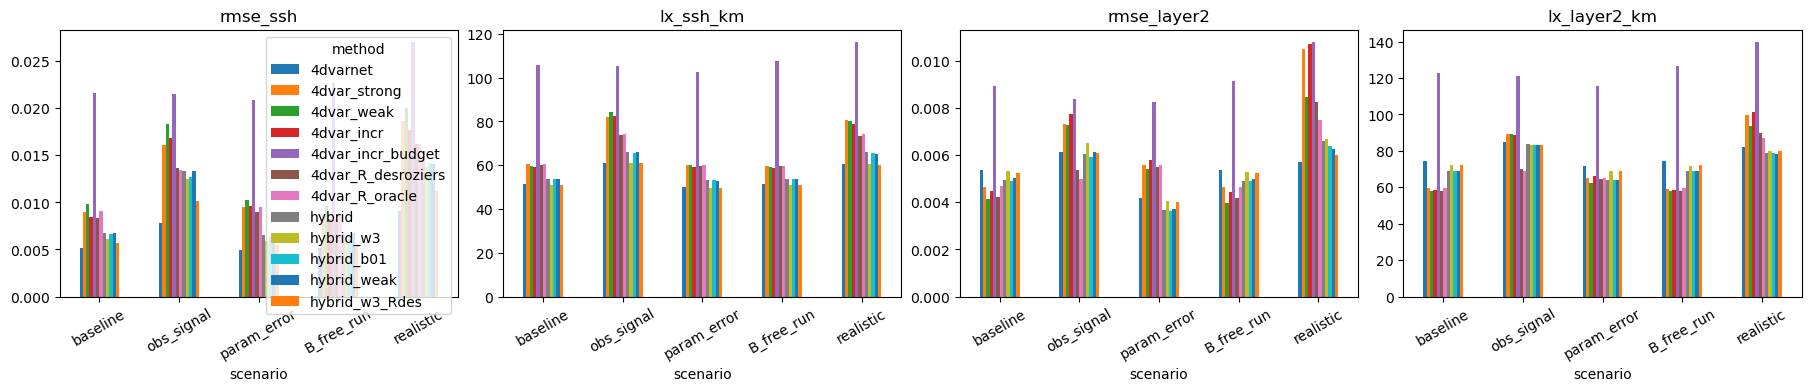

In [9]:
METHOD_ORDER = ["4dvarnet", "4dvar_strong", "4dvar_weak", "4dvar_incr", "4dvar_incr_budget", "4dvar_R_desroziers",
                "4dvar_R_oracle", "hybrid", "hybrid_w3", "hybrid_b01", "hybrid_weak", "hybrid_w3_Rdes"]
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8), constrained_layout=True)
for a, key in zip(ax, ["rmse_ssh", "lx_ssh_km", "rmse_layer2", "lx_layer2_km"]):
    tab = scores[key].unstack("method").reindex(columns=[m for m in METHOD_ORDER if m in scores.index.get_level_values(1)])
    tab.loc[list(RESULTS)].plot.bar(ax=a, legend=a is ax[0], rot=30)
    a.set_title(key)

## 5. Error energy per Lyapunov subspace

In [10]:
SUBS = ["blv_unstable_abs", "blv_neutral_abs", "blv_stable_resolved_abs", "residual_abs"]
rows = []
for n, r in RESULTS.items():
    if r["lyap"] is None:
        continue
    for m, v in r["lyap"]["methods"].items():
        rows.append(dict(scenario=n, method=m, n_unstable=r["lyap"]["n_unstable"],
                         total=v["mean_error_energy"], **{s: v["mean_" + s] for s in SUBS},
                         angle_us_deg=v.get("mean_angle_us_deg", np.nan)))
lyap_tab = pd.DataFrame(rows).set_index(["scenario", "method"])
lyap_tab

n_unstable     total  blv_unstable_abs  \
scenario    method                                                       
baseline    4dvarnet                    73  0.001320          0.000113   
            4dvar_strong                73  0.001633          0.000382   
            4dvar_weak                  73  0.001534          0.000371   
            4dvar_incr                  73  0.001505          0.000339   
            4dvar_incr_budget           73  0.006526          0.001734   
            hybrid                      73  0.001278          0.000204   
            4dvar_R_desroziers          73  0.001494          0.000333   
            4dvar_R_oracle              73  0.001633          0.000384   
            hybrid_w3                   73  0.001213          0.000145   
            hybrid_b01                  73  0.001263          0.000197   
            hybrid_weak                 73  0.001260          0.000196   
            hybrid_w3_Rdes              73  0.001184          0.000133   
obs_signal  4dvarnet                    73  0.002363          0.000255   
            4dvar_strong                73  0.003941          0.001341   
            4dvar_weak                  73  0.004228          0.001476   
            4dvar_incr                  73  0.004036          0.001351   
            4dvar_incr_budget           73  0.006329          0.001778   
            hybrid                      73  0.002829          0.000766   
            4dvar_R_desroziers          73  0.002843          0.001018   
            4dvar_R_oracle              73  0.002778          0.000998   
            hybrid_w3                   73  0.002583          0.000559   
            hybrid_b01                  73  0.002691          0.000702   
            hybrid_weak                 73  0.002765          0.000731   
            hybrid_w3_Rdes              73  0.002194          0.000393   
param_error 4dvarnet                    80  0.001113          0.000106   
            4dvar_strong                80  0.001843          0.000464   
            4dvar_weak                  80  0.001847          0.000491   
            4dvar_incr                  80  0.001852          0.000464   
            4dvar_incr_budget           80  0.006432          0.001810   
            hybrid                      80  0.001097          0.000206   
            4dvar_R_desroziers          80  0.001725          0.000411   
            4dvar_R_oracle              80  0.001838          0.000462   
            hybrid_w3                   80  0.001002          0.000136   
            hybrid_b01                  80  0.001080          0.000196   
            hybrid_weak                 80  0.001075          0.000193   
            hybrid_w3_Rdes              80  0.000976          0.000124   
B_free_run  4dvarnet                    73  0.001320          0.000113   
            4dvar_strong                73  0.001579          0.000361   
            4dvar_weak                  73  0.001502          0.000361   
            4dvar_incr                  73  0.001457          0.000326   
            4dvar_incr_budget           73  0.006729          0.001827   
            hybrid                      73  0.001272          0.000202   
            4dvar_R_desroziers          73  0.001461          0.000326   
            4dvar_R_oracle              73  0.001582          0.000361   
            hybrid_w3                   73  0.001212          0.000145   
            hybrid_b01                  73  0.001257          0.000195   
            hybrid_weak                 73  0.001259          0.000197   
            hybrid_w3_Rdes              73  0.001180          0.000131   
realistic   4dvarnet                    75  0.002592          0.000327   
            4dvar_strong                75  0.005766          0.001782   
            4dvar_weak                  75  0.005337          0.001720   
            4dvar_incr                  75  0.005441          0.001690   
            4dvar_incr_budget       

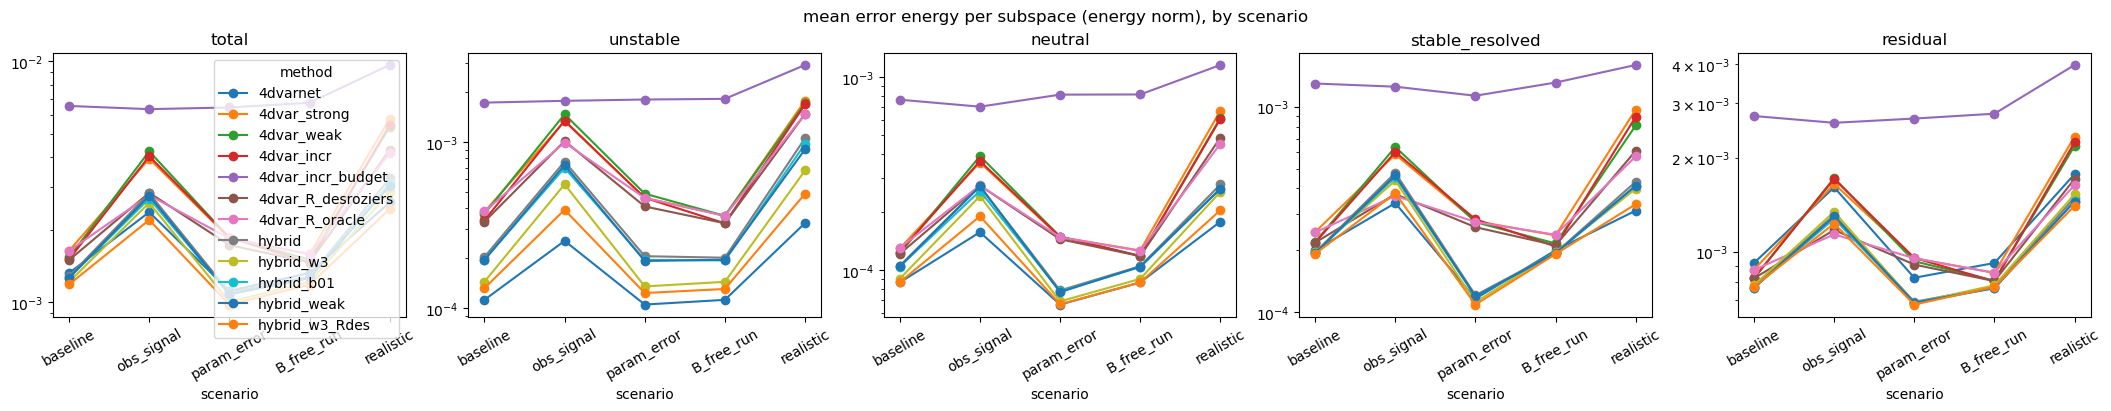

In [11]:
fig, ax = plt.subplots(1, len(SUBS) + 1, figsize=(4.2 * (len(SUBS) + 1), 4), constrained_layout=True, sharey=False)
for a, key in zip(ax, ["total"] + SUBS):
    tab = lyap_tab[key].unstack("method")
    tab = tab.reindex(columns=[m for m in METHOD_ORDER if m in tab.columns]).loc[[n for n in RESULTS if n in tab.index]]
    tab.plot(ax=a, marker="o", logy=True, legend=a is ax[0], rot=30)
    a.set_title(key.replace("_abs", "").replace("blv_", ""))
    a.set_xticks(range(len(tab))); a.set_xticklabels(tab.index, rotation=30)
fig.suptitle("mean error energy per subspace (energy norm), by scenario");

In [12]:
# relative gain of 4DVarNet over the strong-constraint 4DVar per subspace: > 0 means 4DVarNet is better
gain = (1 - lyap_tab.xs("4dvarnet", level="method")[["total"] + SUBS]
        / lyap_tab.xs("4dvar_strong", level="method")[["total"] + SUBS])
gain.round(3)

,total,blv_unstable_abs,blv_neutral_abs,blv_stable_resolved_abs,residual_abs
scenario,,,,,
baseline,0.192,0.705,0.333,0.185,-0.052
obs_signal,0.400,0.810,0.564,0.421,0.025
param_error,0.396,0.772,0.552,0.581,0.135
B_free_run,0.164,0.688,0.316,0.153,-0.076
realistic,0.550,0.817,0.734,0.678,0.243


## 5b. Observation-error statistics used by the 4DVars

`nominal` = instrumental noise only; `desroziers` = per-satellite std estimated from innovation statistics on the
validation split (2 fixed-point iterations, no truth); `oracle` = actual std of obs − truth. With unresolved signal
in the observations (`obs_signal`, `realistic`) the nominal R is badly misspecified: compare `4dvar_strong`,
`4dvar_R_desroziers` and `4dvar_R_oracle` before concluding on these scenarios.

In [13]:
import xarray as xr

rows = []
for n, r in RESULTS.items():
    obs_std = r["obs_summary"].get("obs_minus_truth_std_m")
    for m in ["4dvar_R_desroziers", "4dvar_R_oracle", "hybrid_w3_Rdes"]:
        if m in r["recs"]:
            info = json.loads(xr.open_dataset(r["recs"][m], decode_times=False).attrs["config"]).get("r_info", {})
            est = info.get("desroziers", [None])[-1] if "desroziers" in info else info.get("oracle")
            rows.append(dict(scenario=n, method=m, obs_minus_truth_std=obs_std,
                             **{f"sigma_sat{k}": v for k, v in (est or {}).items()}))
pd.DataFrame(rows).set_index(["scenario", "method"]).round(4)

obs_minus_truth_std  sigma_sat0  sigma_sat1  \
scenario    method                                                            
baseline    4dvar_R_desroziers               0.0060      0.0111      0.0107   
            4dvar_R_oracle                   0.0060      0.0100      0.0099   
            hybrid_w3_Rdes                   0.0060      0.0150      0.0128   
obs_signal  4dvar_R_desroziers               0.0147      0.0143      0.0135   
            4dvar_R_oracle                   0.0147      0.0170      0.0169   
            hybrid_w3_Rdes                   0.0147      0.0186      0.0160   
param_error 4dvar_R_desroziers               0.0060      0.0101      0.0106   
            4dvar_R_oracle                   0.0060      0.0100      0.0099   
            hybrid_w3_Rdes                   0.0060      0.0118      0.0118   
B_free_run  4dvar_R_desroziers               0.0060      0.0111      0.0107   
            4dvar_R_oracle                   0.0060      0.0100      0.0099   
            hybrid_w3_Rdes                   0.0060      0.0152      0.0129   
realistic   4dvar_R_desroziers               0.0153      0.0142      0.0137   
            4dvar_R_oracle                   0.0153      0.0173      0.0170   
            hybrid_w3_Rdes                   0.0153      0.0178      0.0162   

                                sigma_sat2  sigma_sat3  
scenario    method                                      
baseline    4dvar_R_desroziers      0.0110      0.0050  
            4dvar_R_oracle          0.0100      0.0030  
            hybrid_w3_Rdes          0.0139      0.0111  
obs_signal  4dvar_R_desroziers      0.0149      0.0103  
            4dvar_R_oracle          0.0168      0.0138  
            hybrid_w3_Rdes          0.0180      0.0160  
param_error 4dvar_R_desroziers      0.0100      0.0045  
            4dvar_R_oracle          0.0100      0.0030  
            hybrid_w3_Rdes          0.0117      0.0082  
B_free_run  4dvar_R_desroziers      0.0110      0.0050  
            4dvar_R_oracle          0.0100      0.0030  
            hybrid_w3_Rdes          0.0139      0.0112  
realistic   4dvar_R_desroziers      0.0135      0.0101  
            4dvar_R_oracle          0.0170      0.0145  
            hybrid_w3_Rdes          0.0174      0.0156

## 5c. Confidence intervals (paired moving-block bootstrap over test days)

Ratio = E_ref / E_method per subspace (> 1: the method has less error than the reference), 90 % intervals,
blocks of 10 days (~ Lyapunov time), same blocks for all methods (paired). `p_better` = bootstrap probability that
the ratio is > 1.

In [14]:
from contrib.qg2l.stats import subspace_ci_from_file

REF = "4dvar_strong"
CI_METHODS = ["4dvarnet", "4dvar_R_desroziers", "4dvar_R_oracle", "hybrid", "hybrid_w3", "hybrid_w3_Rdes"]
ci = []
for n, r in RESULTS.items():
    f = r["diag_dir"] / "lyapunov_projection.nc"
    if f.exists():
        for row in subspace_ci_from_file(f, ref=REF, block=10, n_boot=2000, level=0.9):
            ci.append(dict(scenario=n, **row))
ci = pd.DataFrame(ci)
tab = ci[ci.method.isin(CI_METHODS)].copy()
tab["ratio [90% CI]"] = tab.apply(lambda r: f"{r.ratio:.2f} [{r.ratio_lo:.2f}, {r.ratio_hi:.2f}]", axis=1)
tab.pivot_table(index=["scenario", "method"], columns="subspace", values="ratio [90% CI]", aggfunc="first")

subspace                                  neutral           residual  \
scenario    method                                                     
B_free_run  4dvar_R_desroziers  1.07 [1.03, 1.11]  1.06 [1.05, 1.07]   
            4dvar_R_oracle      1.00 [1.00, 1.01]  1.00 [1.00, 1.00]   
            4dvarnet            1.46 [1.19, 1.81]  0.93 [0.87, 0.98]   
            hybrid              1.21 [0.98, 1.51]  1.11 [1.06, 1.16]   
            hybrid_w3           1.40 [1.13, 1.76]  1.10 [1.03, 1.16]   
            hybrid_w3_Rdes      1.46 [1.17, 1.84]  1.11 [1.05, 1.17]   
baseline    4dvar_R_desroziers  1.07 [1.03, 1.11]  1.07 [1.06, 1.07]   
            4dvar_R_oracle      0.99 [0.98, 1.00]  1.00 [1.00, 1.00]   
            4dvarnet            1.50 [1.23, 1.85]  0.95 [0.89, 1.01]   
            hybrid              1.23 [0.99, 1.53]  1.13 [1.08, 1.19]   
            hybrid_w3           1.44 [1.15, 1.80]  1.12 [1.06, 1.18]   
            hybrid_w3_Rdes      1.50 [1.20, 1.87]  1.13 [1.07, 1.20]   
obs_signal  4dvar_R_desroziers  1.32 [1.22, 1.41]  1.41 [1.37, 1.45]   
            4dvar_R_oracle      1.32 [1.21, 1.42]  1.45 [1.41, 1.49]   
            4dvarnet            2.30 [2.14, 2.46]  1.03 [0.97, 1.08]   
            hybrid              1.33 [1.25, 1.41]  1.26 [1.20, 1.32]   
            hybrid_w3           1.49 [1.43, 1.57]  1.23 [1.17, 1.29]   
            hybrid_w3_Rdes      1.90 [1.82, 2.00]  1.34 [1.28, 1.41]   
param_error 4dvar_R_desroziers  1.03 [0.98, 1.07]  1.05 [1.03, 1.07]   
            4dvar_R_oracle      1.00 [0.99, 1.01]  1.00 [1.00, 1.00]   
            4dvarnet            2.23 [1.83, 2.73]  1.16 [1.10, 1.21]   
            hybrid              1.89 [1.63, 2.20]  1.38 [1.31, 1.45]   
            hybrid_w3           2.15 [1.80, 2.55]  1.39 [1.32, 1.46]   
            hybrid_w3_Rdes      2.23 [1.84, 2.68]  1.41 [1.34, 1.48]   
realistic   4dvar_R_desroziers  1.38 [1.27, 1.49]  1.37 [1.31, 1.43]   
            4dvar_R_oracle      1.48 [1.35, 1.62]  1.43 [1.35, 1.52]   
            4dvarnet            3.76 [3.24, 4.29]  1.32 [1.24, 1.40]   
            hybrid              2.41 [2.09, 2.72]  1.57 [1.50, 1.64]   
            hybrid_w3           2.63 [2.26, 3.02]  1.53 [1.44, 1.63]   
            hybrid_w3_Rdes      3.28 [2.83, 3.76]  1.67 [1.58, 1.77]   

subspace                          stable_resolved              total  \
scenario    method                                                     
B_free_run  4dvar_R_desroziers  1.12 [1.08, 1.15]  1.08 [1.07, 1.09]   
            4dvar_R_oracle      0.99 [0.98, 1.00]  1.00 [0.99, 1.00]   
            4dvarnet            1.18 [1.00, 1.39]  1.20 [1.11, 1.29]   
            hybrid              1.21 [1.04, 1.42]  1.24 [1.15, 1.35]   
            hybrid_w3           1.20 [1.02, 1.41]  1.30 [1.20, 1.41]   
            hybrid_w3_Rdes      1.23 [1.06, 1.43]  1.34 [1.24, 1.45]   
baseline    4dvar_R_desroziers  1.13 [1.08, 1.17]  1.09 [1.08, 1.11]   
            4dvar_R_oracle      1.00 [1.00, 1.01]  1.00 [0.99, 1.01]   
            4dvarnet            1.23 [1.04, 1.44]  1.24 [1.15, 1.34]   
            hybrid              1.26 [1.07, 1.46]  1.28 [1.18, 1.39]   
            hybrid_w3           1.25 [1.06, 1.47]  1.35 [1.24, 1.46]   
            hybrid_w3_Rdes      1.28 [1.10, 1.48]  1.38 [1.28, 1.50]   
obs_signal  4dvar_R_desroziers  1.56 [1.50, 1.63]  1.39 [1.33, 1.44]   
            4dvar_R_oracle      1.59 [1.52, 1.66]  1.42 [1.37, 1.47]   
            4dvarnet            1.73 [1.53, 1.96]  1.67 [1.58, 1.76]   
            hybrid              1.23 [1.11, 1.36]  1.39 [1.33, 1.47]   
            hybrid_w3           1.34 [1.19, 1.50]  1.53 [1.45, 1.61]   
            hybrid_w3_Rdes      1.55 [1.36, 1.77]  1.80 [1.70, 1.89]   
param_error 4dvar_R_desroziers  1.07 [1.03, 1.11]  1.07 [1.04, 1.10]   
            4dvar_R_oracle      1.01 [1.00, 1.02]  1.00 [1.00, 1.01]   
            4dvarnet            2.39 [2.00, 2.85]  1.66 [1.54, 1.78]   
            hybrid              2.30 [2

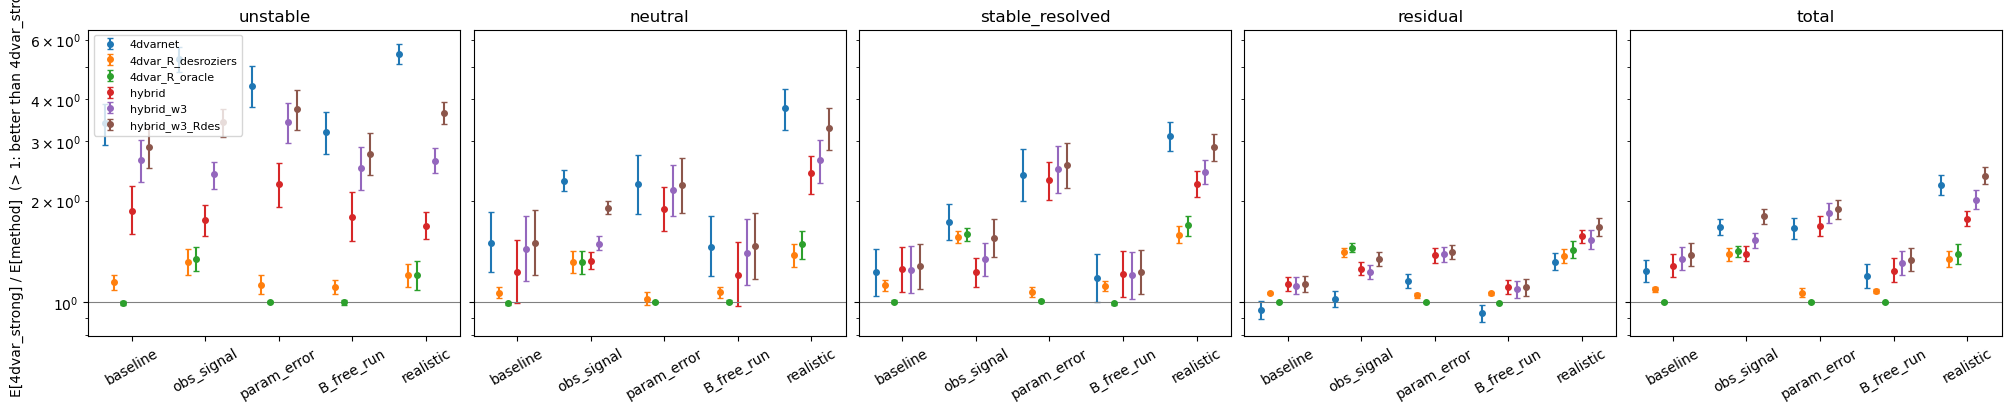

In [15]:
subs = ["unstable", "neutral", "stable_resolved", "residual", "total"]
show = [m for m in CI_METHODS if m in set(ci.method)]
fig, axes = plt.subplots(1, len(subs), figsize=(4 * len(subs), 4), sharey=True, constrained_layout=True)
scen = [n for n in RESULTS if n in set(ci.scenario)]
for ax, sub in zip(axes, subs):
    for j, m in enumerate(show):
        d = ci[(ci.subspace == sub) & (ci.method == m)].set_index("scenario").reindex(scen)
        x = np.arange(len(scen)) + (j - len(show) / 2) * 0.12
        ax.errorbar(x, d.ratio, yerr=[d.ratio - d.ratio_lo, d.ratio_hi - d.ratio], fmt="o", ms=4, capsize=2,
                    label=m)
    ax.axhline(1, c="gray", lw=0.8)
    ax.set_yscale("log"); ax.set_title(sub)
    ax.set_xticks(range(len(scen))); ax.set_xticklabels(scen, rotation=30)
axes[0].set_ylabel(f"E[{REF}] / E[method]  (> 1: better than {REF})")
axes[0].legend(fontsize=8);

## 6. Detailed diagnostic of one scenario

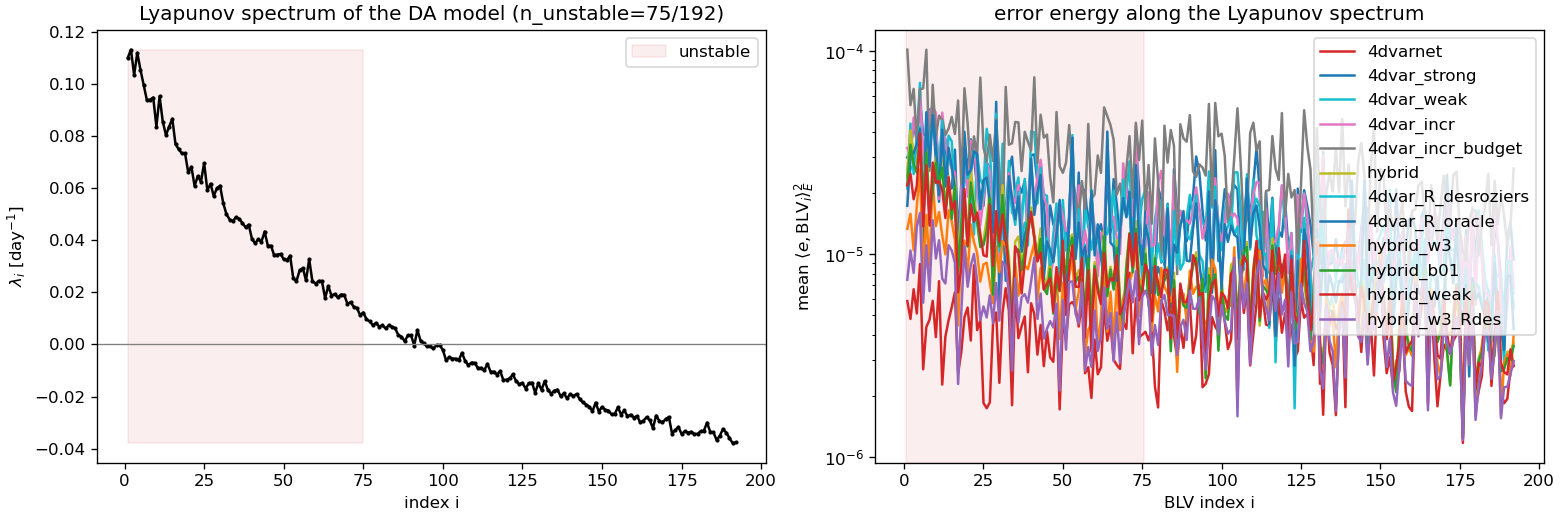

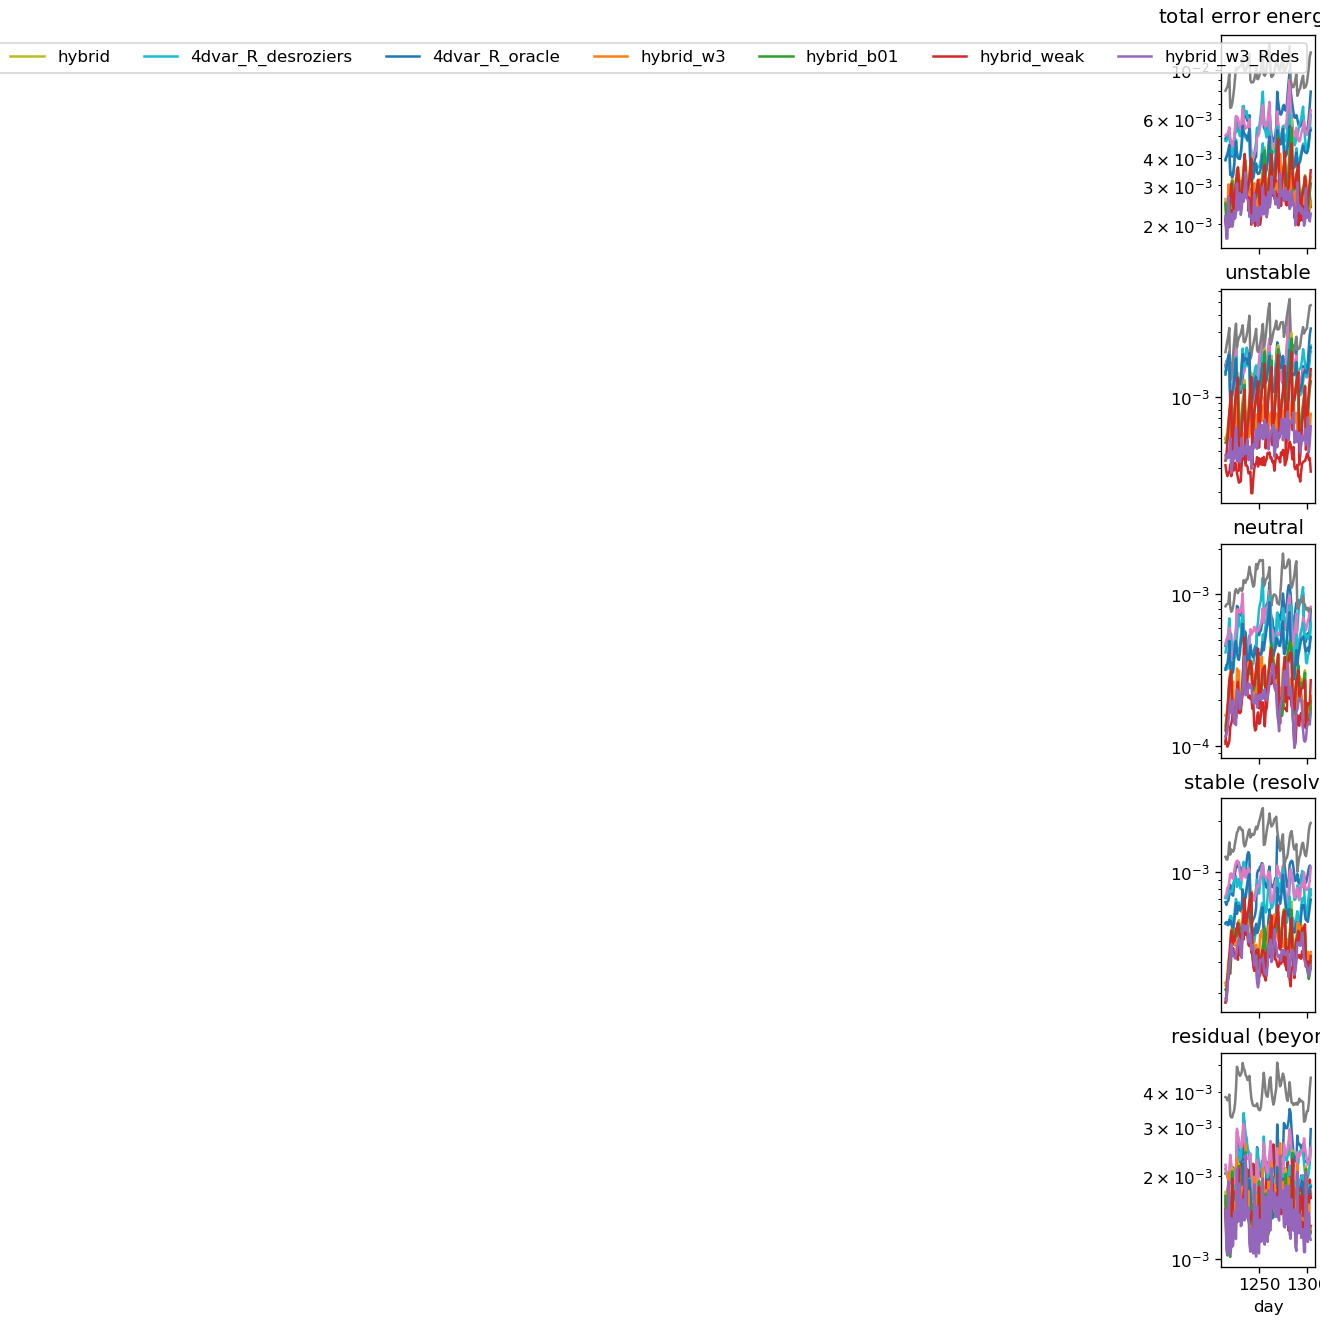

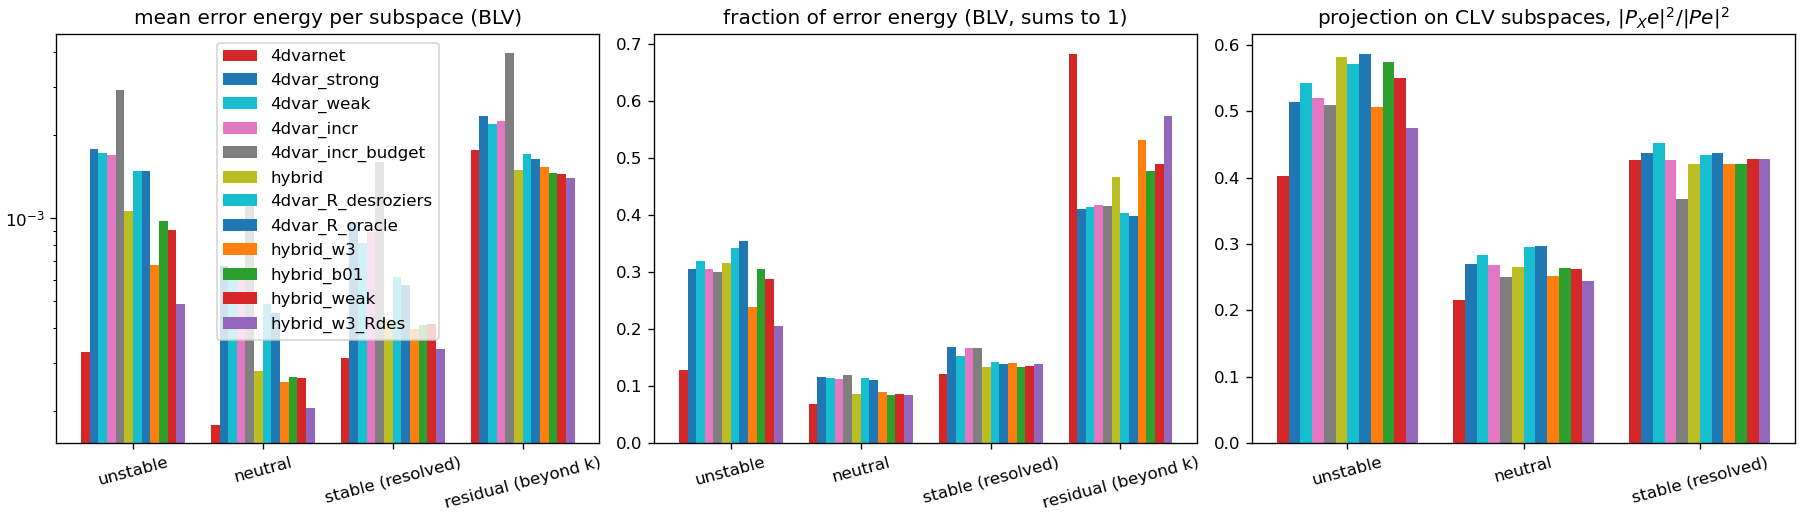

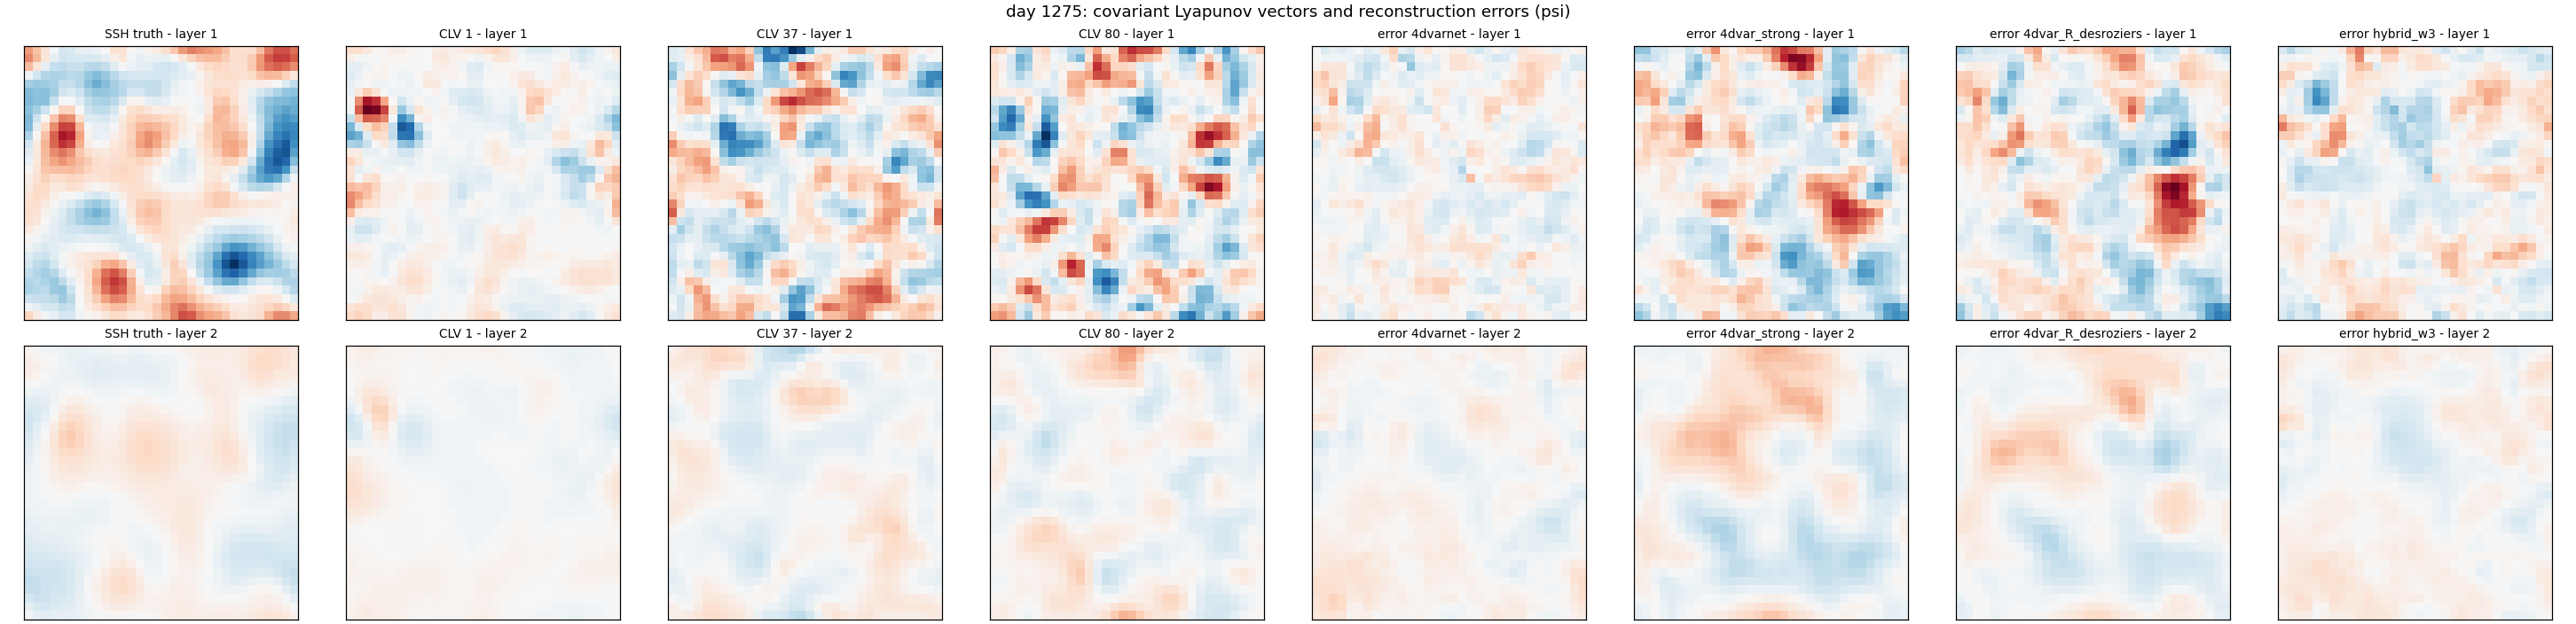

In [16]:
SHOW = "realistic" if "realistic" in RESULTS else list(RESULTS)[0]
d = RESULTS[SHOW]["diag_dir"]
for f in ["lyapunov_spectrum_error_distribution.png", "error_energy_by_subspace.png", "subspace_summary.png",
          "clv_and_error_maps.png"]:
    if (d / f).exists():
        display(Image(filename=str(d / f)))
anim = d / "reconstructions.mp4"
if anim.exists():
    display(Video(str(anim), embed=True, width=1100))

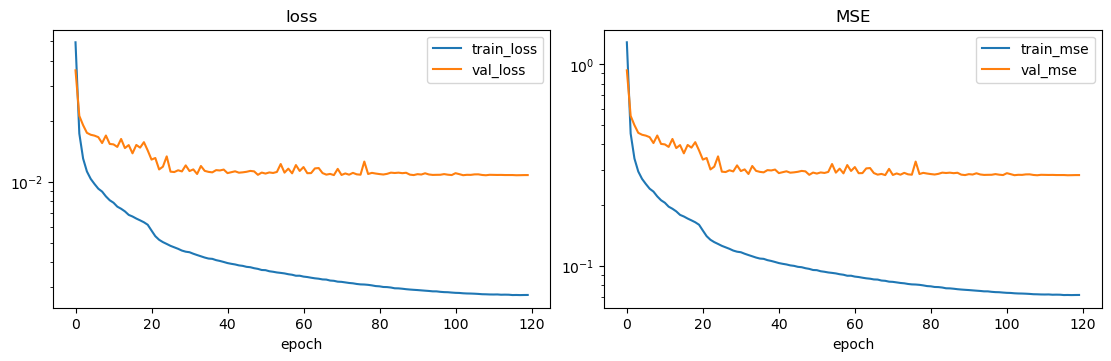

In [17]:
# 4DVarNet training curves for that scenario
hist = pipeline.training_curves(RESULTS[SHOW]["recs"]["4dvarnet"])
if not hist.empty:
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)
    hist[[c for c in ["train_loss", "val_loss"] if c in hist]].dropna(how="all").plot(ax=ax[0], logy=True)
    hist[[c for c in ["train_mse", "val_mse"] if c in hist]].dropna(how="all").plot(ax=ax[1], logy=True)
    ax[0].set_title("loss"); ax[1].set_title("MSE")

## 7. Reading the results

* **unstable** column: controlled by observability + optimisation. A dynamically consistent estimate (4DVar) lets its
  error grow along these directions within each window (saw-tooth in `error_energy_by_subspace.png`); the learned
  smoother does not have to be a model trajectory.
* **stable / residual** columns: in the baseline, 4DVar gets them almost for free from the exact dynamics. Model
  error (`param_error`, `forcing`) and unresolved signal in the obs (`obs_signal`) should erode this advantage;
  if it persists, the learned prior is the bottleneck (try a richer prior / more data).
* **4dvar_incr vs 4dvar_strong**: operational incremental solver vs (near) converged nonlinear minimisation.
  **4dvar_incr_budget**: what is left of a properly preconditioned 4DVar at a few TL/AD integrations per window
  (compare with the cost of a 4DVarNet forward pass in the cost table).
* **hybrid**: if it beats both, the two error structures are complementary (4DVarNet fixes the unstable part, the
  short 4DVar re-imposes dynamical consistency on the stable part).
* Tune `b_scale` / `q_scale` / window on the validation split before final conclusions (`split="val"` in a method dict).